In [11]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

#import data
img = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')[0]

In [12]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

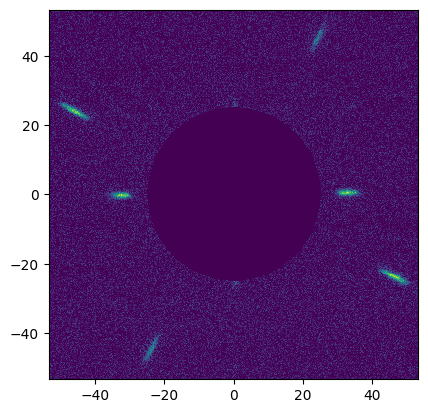

In [13]:
img = ADC.crop_image(img,mask_diam=50)

imshow_field(img)

ncpc speckle


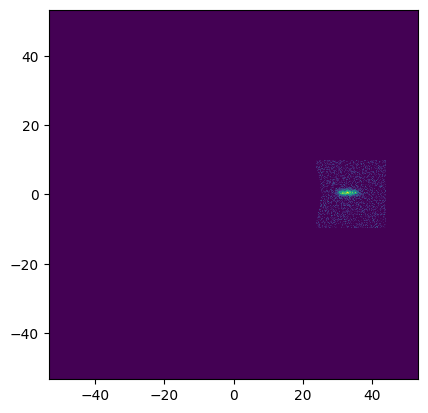

In [15]:
speckle_number = 0

ncpc = True
ncpc_freq = 29

extent=20

if ncpc != True:
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-grating_angle))(img.grid)
else:
    speckle_coords = np.array([[ncpc_freq * ADC.normalized_wavelength,0],[ADC.grating_freq * ADC.normalized_wavelength,0],[-ncpc_freq * ADC.normalized_wavelength,0],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    if speckle_number==0 or speckle_number==2:
        rect = make_rectangular_aperture(size=(extent,extent), center=speckle_center)(img.grid)
        print('ncpc speckle')
    else:
        rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-grating_angle))(img.grid)
        print('tweeter speckle')

#cut out the speckle area

speckle_img = rect * img

imshow_field(speckle_img)

In [39]:
def isolate_ncpc_speckle(img,speckle_number):
    ncpc_freq = 29
    speckle_coords = np.array([[ncpc_freq * ADC.normalized_wavelength,0],[ADC.grating_freq * ADC.normalized_wavelength,0],[-ncpc_freq * ADC.normalized_wavelength,0],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    rect = make_rectangular_aperture(size=(extent,extent), center=speckle_center)(img.grid)
    speckle_img = rect * img
    return speckle_img

In [104]:
#now let's make sure the fitter works ok on the ncpc speckles
##functions
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

def slice_speckle_angle(img,speckle_number,ncpc=False,print_updates=False):
        '''calculate the angle of a single speckle using the gaussian slicing method. image must be an hcipy field.
        returns the slope of the designated speckle in degrees.'''
    
        #locate the general area of the speckle
        extent=20
        ncpc_freq = 29

        if ncpc == False: #if we're not using the ncpc speckles, proceed as normal
            speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
            speckle_center = speckle_coords[speckle_number]
            rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)
        else: #if we are, there's a different rotation angle for speckles 1&3 and 2&4
            speckle_coords = np.array([[ncpc_freq * ADC.normalized_wavelength,0],[ADC.grating_freq * ADC.normalized_wavelength,0],[-ncpc_freq * ADC.normalized_wavelength,0],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
            speckle_center = speckle_coords[speckle_number]
            if speckle_number==0 or speckle_number==2:
                rect = make_rectangular_aperture(size=(extent,extent), center=speckle_center)(img.grid)
            else:
                rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

        speckle_img = rect * img

        #find the center of intensity of the speckle area and window the ORIGINAL image around that center
        center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
        
        # if ncpc==True and speckle_number %2 ==0:
        #     window_size = 50
        #     print('ncpc speckle - changed window size')
        # else: window_size=50

        window_size = 50
        new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)
        
        shaped = new_img.shaped
        mus = np.zeros(shaped.shape[0])


        ## if ncpc - slice them all vertically
        ## if not ncpc - slice 2 and 4 vertically, 1 and 3 horizontally

        for i in range(shaped.shape[0]):
            if ncpc==True:
                sliced = shaped[:,i] 
                #print('slicing vertically')
            elif speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
                sliced = shaped[:,i] 
                #print('slicing vertically')
            else: 
                sliced = shaped[i,:]
                #print('slicing horizontally')

            zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

            if zscore > 2:
                s = isolate_gaussian(sliced)
                s /= s.max()
                m, std, fwhm = mu(s)
                mus[i] = m
            else: mus[i] = -1

        #take the second derivative so we can isolate the nonlinear region
        deriv2 = np.gradient(np.gradient(mus))
        nonlin_region = np.atleast_1d(np.squeeze(np.where(np.abs(deriv2) >= 0.4)))

        #start from the middle of the mu vector and move outward to find the bounds of the linear region
        midpoint = int(np.floor(window_size / 2))
        leftbound = nonlin_region[nonlin_region < midpoint][-1] if any(nonlin_region < midpoint) else None
        rightbound = nonlin_region[nonlin_region > midpoint][0] if any(nonlin_region > midpoint) else None

        #do a linear regression on the mus in the linear region. if there is no clear linear region, print an error if print_updates is enabled.
        if leftbound is not None and rightbound is not None:
            linear_region = mus[leftbound:rightbound]
            lin_x = np.arange(len(linear_region))

            m , b = np.polyfit(lin_x,linear_region,deg=1)
            angle = np.arctan(m)
            if print_updates ==True:
                print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

            return np.degrees(angle) #returns the slope of the individual speckle in degrees.
        else: 
            if print_updates == True:
                print(f'unable to fit speckle {speckle_number}')
            return np.nan



#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        #print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles


-5.588799936932734


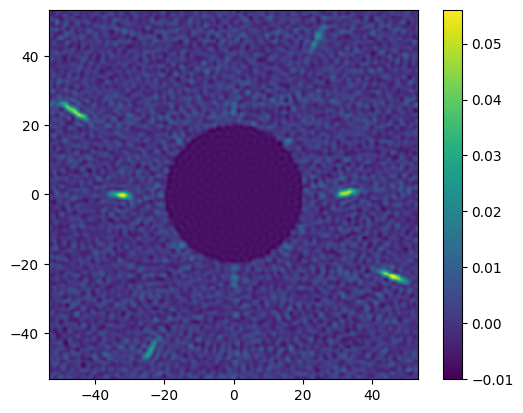

In [106]:
field =  read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/sparkles_sweep.fits')[0]
filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=40)) 

imshow_field(filtered)
plt.colorbar()
a = slice_speckle_angle(filtered,speckle_number=2,ncpc=True)
print(a)

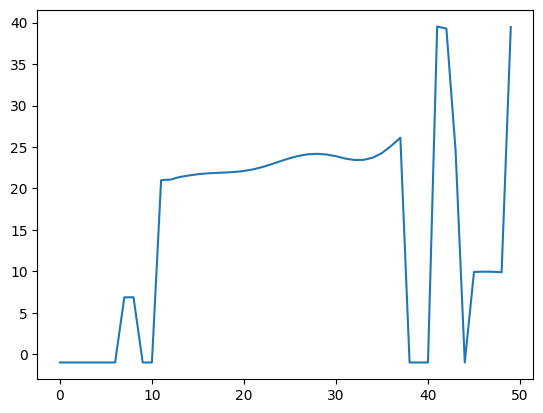

In [102]:
plt.plot(a)